In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from cycler import cycler

Figure saved as gpu_power.pdf


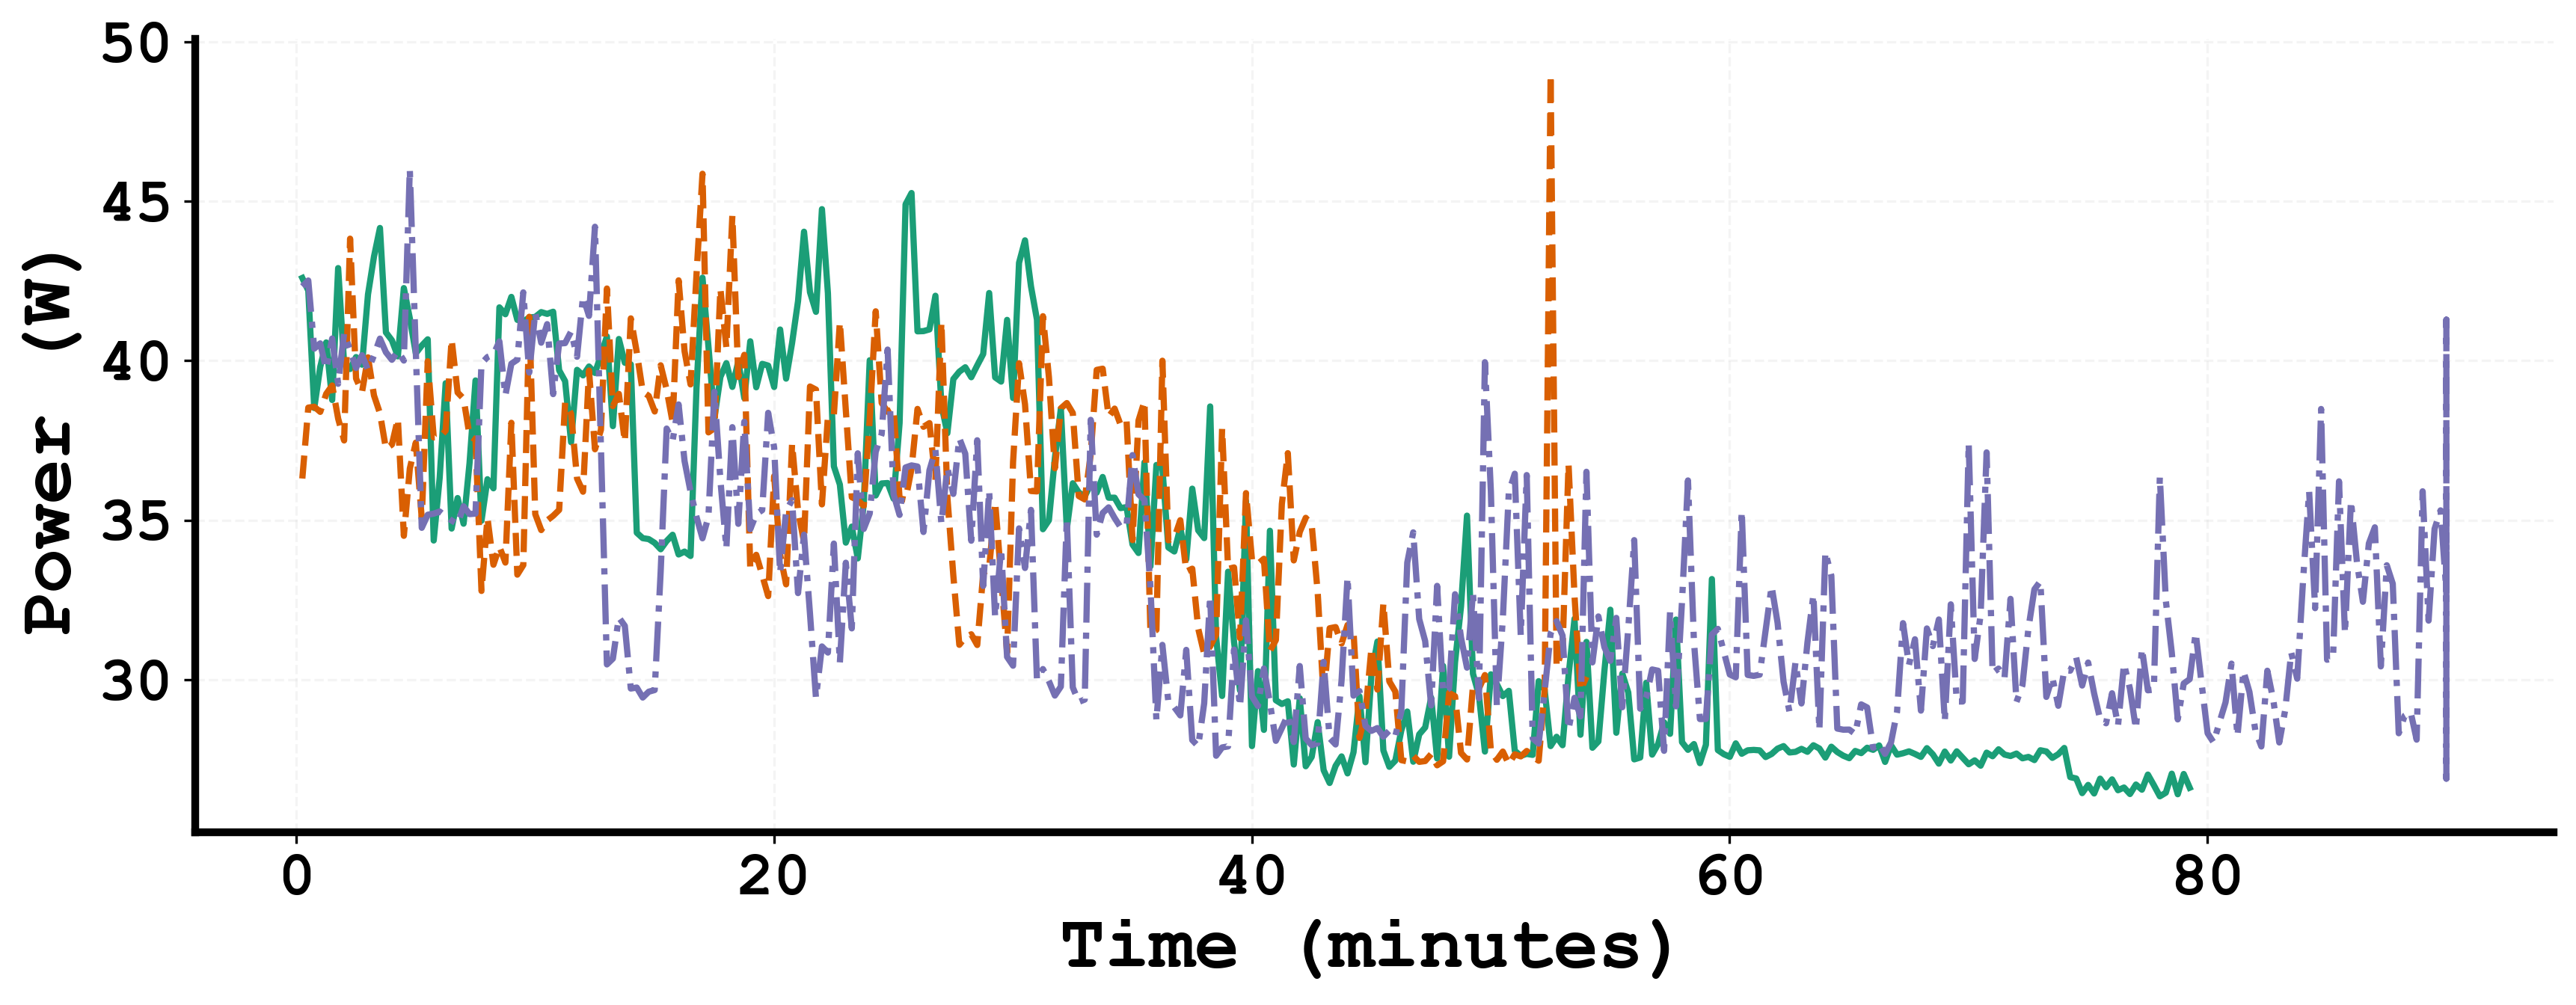

In [13]:
# Load data
csv_path = 'wandb_export_2025-06-07T02_42_05.439-07_00.csv'
df = pd.read_csv(csv_path)

# Clean and convert time to minutes
df['Relative Time (Process)'] = pd.to_numeric(df['Relative Time (Process)'], errors='coerce')
df = df.dropna(subset=['Relative Time (Process)'])
df['Time_min'] = df['Relative Time (Process)'] / 60.0

start_time = 0
end_time = 90

df['Time_min'] = df['Time_min'].clip(lower=start_time, upper=end_time)
# Define series
series_info = [
    ('SoftUpdateBigTau - system/gpu.0.powerWatts', 'SoftUpdateBigTau'),
    ('HardUpdateBigC - system/gpu.0.powerWatts', 'HardUpdateBigC'),
    ('DQN - system/gpu.0.powerWatts', 'DQN')
]

# Journal-friendly colors and line styles
colors = ['#1b9e77', '#d95f02', '#7570b3']
linestyles = ['-', '--', '-.']
plt.rcParams['axes.prop_cycle'] = cycler('color', colors) + cycler('linestyle', linestyles)

# Base style
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Courier New'],
    'font.size': 24,           # doubled from 12
    'axes.labelsize': 24,      # doubled from 12
    'axes.labelweight': 'bold',  # make axis labels bold
    'xtick.labelsize': 20,     # doubled from 10
    'ytick.labelsize': 20,     # doubled from 10
    'legend.fontsize': 20,     # doubled from 10
    'figure.dpi': 300,
    'figure.figsize': (12, 5),
    'lines.linewidth': 2,
    'axes.linewidth': 2.5,     # thicker axis lines
    'axes.grid': True,
    'grid.color': '#CCCCCC',
    'grid.linestyle': '--',
    'grid.alpha': 0.2
})


# Plotting
fig, ax = plt.subplots()
for col, label in series_info:
    if col in df.columns:
        d = df.dropna(subset=[col])
        ax.plot(
            d['Time_min'], d[col], 
            label=label
        )

# Remove top and right spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Labels and legend
ax.set_xlabel('Time (minutes)', fontweight='bold')
ax.set_ylabel('Power (W)', fontweight='bold')

plt.tight_layout()
# Save as PDF
output_pdf = 'gpu_power.pdf'
fig.savefig(output_pdf, format='pdf', bbox_inches='tight')
print(f"Figure saved as {output_pdf}")
